# Week 5: Feature Engineering

============================================================

IDX Exchange — Data Science Internship

Week 5: Feature Engineering

Author: Zachary Blehm

============================================================

Summary:

This notebook modified the 02_preprocessing notebook. There were three parts to the modification
1. Removing low correlation features - some of the features previously kept havd very low correlation to ClosePrice, for example ParkingTotal. These features, and any associated features (such as missingness) were removed.
2. Modifications to the data processing - The zip level aggregates and knn comps are now based on a moving window rather than an expanding window. The previous implementation considered all past listing for the corresponding features, but now a standardized moving window (default 6 months) is used.
3. Additional feature engineering - New features were added including price per square foot, area and relative age (listing age - comp age) to the knn comps. Additionally a new set of knn comps was created based on "similar" listing defined as listing with the same numner of bedrooms and bathroom and within +/- 10% of the living area. These "similar" comps have all the same columns as the regular knn comps. Finally there is a time adjusted price feature that uses the knn comp price and the zip level price trend to calculate an updated median comp value. The new features are summarized in the table below.

| Column Name | Description |
|----------|----------|
| bed_bath_ratio   | BedroomsTotal / BathroomsTotalInteger  |
| knn_#_median_ppsft    | Price Per Square Foot of the comp  |
| knn_#_median_area    | LivingArea of the comp  |
| knn_#_rel_age   | Difference in age of listing and the comp  |
| knn_#_similar_median_price    | ClosePrice of the similar comp  |
| knn_#_similar_median_ppsft    | Price Per Square Foot of the similar comp |
| knn_#_similar_median_area    | LivingArea of the similar comp  |
| knn_#_similar_rel_age   | Difference in age of listing and the similar comp  |
| knn_#_time_adjusted_price | Normalized comp price using the knn median price and the zip level price trend |




In [1]:
# Imports and File Loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files
from sklearn.neighbors import NearestNeighbors
import warnings
from numpy.polynomial.polynomial import Polynomial
from numpy.polynomial.polyutils import RankWarning
import geopandas as gpd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [2]:
# 28 months of data total
# Using 6/12 months of data + 6 months of warm-up data for aggregates
# Hold out 202603 for validation & 202604 for testing
data_dir = Path('data')
training_files = [
    # 'CRMLSSold202401_filled.csv',
    # 'CRMLSSold202402.csv',
    # 'CRMLSSold202403_filled.csv',
    # 'CRMLSSold202404_filled.csv',
    # 'CRMLSSold202405_filled.csv',
    # 'CRMLSSold202406_filled.csv',
    # 'CRMLSSold202407_filled.csv',
    # 'CRMLSSold202408.csv',
    'CRMLSSold202409.csv',
    'CRMLSSold202410.csv',
    'CRMLSSold202411.csv',
    'CRMLSSold202412.csv',
    'CRMLSSold202501_filled.csv',
    'CRMLSSold202502.csv',
    'CRMLSSold202503.csv',
    'CRMLSSold202504.csv',
    'CRMLSSold202505.csv',
    'CRMLSSold202506.csv',
    'CRMLSSold202507.csv',
    'CRMLSSold202508.csv',
    'CRMLSSold202509.csv',
    'CRMLSSold202510.csv',
    'CRMLSSold202511.csv',
    'CRMLSSold202512.csv',
    'CRMLSSold202601.csv',
    'CRMLSSold202602.csv',
    'CRMLSSold202603.csv',
    'CRMLSSold202604.csv'
]

dfs = [pd.read_csv(f, low_memory = False) for f in training_files]
df = pd.concat(dfs, ignore_index=True)
print('Combined training shape:', df.shape)

Combined training shape: (428295, 82)


# Initial Filtering of the Data

Filter the data for "Residential" and "SingleFamilyResidence" per the task of predicing home prices.

In [3]:
# Filter the data based on the desired type and subtype

df = df[
    (df['PropertyType'] == 'Residential') &
    (df['PropertySubType'] == 'SingleFamilyResidence')
].copy()
print('After filter:', df.shape)

After filter: (215283, 82)


We consider this our the starting point of cleaning. In logging each removal step the percent removed from the initial dataset is calculated using the number of row at the end of this step as the total value.

# Helper Functions

In [4]:
# Track rows removed/imputed (used by log_step function)
cleaning_log = []

initial_size = len(df)

In [5]:
def log_removal(df_before, df_after, initial_size):
    rows_before = len(df_before)
    rows_after = len(df_after)
    rows_removed = rows_before - rows_after

    pct_removed = (
        round((rows_removed / rows_before) * 100, 3)
        if rows_before else 0
    )

    pct_removed_initial = (
        round((rows_removed / initial_size) * 100, 3)
        if initial_size else 0
    )

    return {
        "Rows Before": rows_before,
        "Rows After": rows_after,
        "Rows Removed": rows_removed,
        "Percent Removed (this step)": pct_removed,
        "Percent Removed (from initial)": pct_removed_initial
    }

In [6]:
def log_imputation(df_before, df_after, initial_size):
    # Count missing cells before and after imputation
    missing_before = int(df_before.isna().sum().sum())
    missing_after = int(df_after.isna().sum().sum())

    num_imputed = missing_before - missing_after
    num_rows = len(df_after)

    pct_imputed = (
        round((num_imputed / num_rows) * 100, 3)
        if num_rows else 0
    )

    pct_imputed_initial = (
        round((num_imputed / initial_size) * 100, 3)
        if initial_size else 0
    )

    return {
        "Missing Values Before": missing_before,
        "Missing Values After": missing_after,
        "Missing Values Imputed": num_imputed,
        "Percent Removed (this step)": pct_imputed,
        "Percent Removed (from initial)": pct_imputed_initial
    }

In [7]:

def log_step(step_description, df_before, df_after, operation, initial_size = initial_size):
    if operation == "removal":
        metrics = log_removal(
            df_before, df_after, initial_size
        )

    elif operation == "imputation":
        metrics = log_imputation(
            df_before, df_after, initial_size
        )

    else:
        raise ValueError(f"Unknown operation: {operation}")

    cleaning_log.append({
        "Step": step_description,
        "Operation": operation,
        **metrics
    })

Keep only the Core property charactersists and a few other columns of interest for further investigation.

In [8]:
def drop_first_n_months(df, n):
    """
    Drops the first n chronological months from the dataset.
    Assumes df has CloseYear and CloseMonth columns.
    """

    df = df.copy()

    # True sequential month index
    df["month_index"] = df["CloseYear"] * 12 + df["CloseMonth"]

    # Earliest month
    min_month = df["month_index"].min()

    # Cutoff month
    cutoff_month = min_month + n

    # Drop first n months
    df_filtered = df[df["month_index"] >= cutoff_month].copy()

    # Remove helper column
    df_filtered.drop(columns=["month_index"], inplace=True)

    return df_filtered


In [9]:
# List of columns to keep for the initial investigation
keep_columns = [
    # Target
    "ClosePrice",

    # Primary Key - use to remove duplicates then drop
    "ListingKey",

    # Core property characteristics
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "LotSizeSquareFeet",
    "YearBuilt",

    # Location
    # Use for filtering to California then dropped
    "StateOrProvince",
    "PostalCode",
    "Latitude",
    "Longitude",

    # Property features
    "FireplaceYN",
    "Stories",
    "Levels",
    "MainLevelBedrooms",

    # HOA
    "AssociationFee",
    "AssociationFeeFrequency",

    # Date
    "CloseDate",
    # Only used to filter illogical listings, then dropped
    "ListingContractDate"
]

df_clean = df[keep_columns].copy()

print("Original shape:", df.shape)
print("Candidate modeling shape:", df_clean.shape)

Original shape: (215283, 82)
Candidate modeling shape: (215283, 19)


# Drop Duplicates

In [10]:
# Remove duplicates (retain most recent)
df_before = df_clean.copy()

df_clean = df_clean.sort_values("CloseDate")
df_clean = df_clean.drop_duplicates(subset="ListingKey", keep="last")

log_step(
    "Remove rows with duplicate listing key (retain most recent)",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

# Drop ListingKey since it is no longer needed
df_clean = df_clean.drop(columns=["ListingKey"])
keep_columns.remove("ListingKey")

{'Step': 'Remove rows with duplicate listing key (retain most recent)',
 'Operation': 'removal',
 'Rows Before': 215283,
 'Rows After': 215109,
 'Rows Removed': 174,
 'Percent Removed (this step)': 0.081,
 'Percent Removed (from initial)': 0.081}

# Datatype Conversion for Numeric and Dates

In [11]:
# Define and then columns that should be numeric type
numeric_columns = [
    "ClosePrice",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "LotSizeSquareFeet",
    "YearBuilt",
    "Latitude",
    "Longitude",
    "Stories",
    "MainLevelBedrooms",
    "AssociationFee"
]

# Convert the numeric columns to numeric type
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

In [12]:
df_clean["CloseDate"] = pd.to_datetime(df_clean["CloseDate"])
df_clean["ListingContractDate"] = pd.to_datetime(df_clean["ListingContractDate"])

# Stadardize PostalCode

In [13]:
# Standardize PostaclCode to 5 digits (i.e. drop extra 4 digits if they exist)
df_clean["PostalCode"] = (
    df_clean["PostalCode"]
    .astype(str)
    .str.extract(r"(\d{5})")  # extract the first 5 digits
)

## Check Null Percentages per Column

In [14]:
# Look at percent missing for each column

print("\nPercentage missing:")
print(
    (df_clean[keep_columns].isna().mean() * 100)
    .round(3)
)


Percentage missing:
ClosePrice                  0.000
BedroomsTotal               0.000
BathroomsTotalInteger       0.012
LivingArea                  0.053
LotSizeSquareFeet           1.729
YearBuilt                   0.074
StateOrProvince             0.000
PostalCode                  0.000
Latitude                    0.105
Longitude                   0.105
FireplaceYN                 0.070
Stories                    11.712
Levels                      8.387
MainLevelBedrooms          39.683
AssociationFee             29.708
AssociationFeeFrequency    74.856
CloseDate                   0.000
ListingContractDate         0.000
dtype: float64


All the primary columns have very low missing value percentages, but we see some columns with double digit missing value percentages that will need special attention and some columns with lower percentage of missing values which will be handled with imputation.

## Remove Rows with NULL values

In [15]:
# Define the primary columns & remove any rows that have a null value
primary_columns = [
    "ClosePrice",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "LotSizeSquareFeet",
    "PostalCode"
]

In [16]:
# Remove rows with NULL for the primary columns
df_before = df_clean.copy()

df_clean = df_clean.dropna(
    subset=primary_columns
).copy()

log_step(
    "Remove rows missing primary fields",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove rows missing primary fields',
 'Operation': 'removal',
 'Rows Before': 215109,
 'Rows After': 211249,
 'Rows Removed': 3860,
 'Percent Removed (this step)': 1.794,
 'Percent Removed (from initial)': 1.793}

## Remove Unrealistic Values

In [17]:
# Remove rows with ClosePrice <= 0
df_before = df_clean.copy()

df_clean = df_clean[
    df_clean["ClosePrice"] > 0
].copy()

log_step(
    "Remove ClosePrice <= 0",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove ClosePrice <= 0',
 'Operation': 'removal',
 'Rows Before': 211249,
 'Rows After': 211248,
 'Rows Removed': 1,
 'Percent Removed (this step)': 0.0,
 'Percent Removed (from initial)': 0.0}

In [18]:
## Remove rows with CloseDate < ListingContractDate
df_before = df_clean.copy()

mask_valid_dates = df_clean["CloseDate"] >= df_clean["ListingContractDate"]

df_clean = df_clean[mask_valid_dates].copy()

log_step(
    "Remove illogical CloseDate before ListingContractDate",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

# Drop ListContractDate since it is no longer needed
df_clean = df_clean.drop(columns=["ListingContractDate"])
keep_columns.remove("ListingContractDate")

{'Step': 'Remove illogical CloseDate before ListingContractDate',
 'Operation': 'removal',
 'Rows Before': 211248,
 'Rows After': 211213,
 'Rows Removed': 35,
 'Percent Removed (this step)': 0.017,
 'Percent Removed (from initial)': 0.016}

In [19]:
# Remove primary columns (less PostalCode) with unrealistic values
df_before = df_clean.copy()

df_clean = df_clean[
    (df_clean["LivingArea"] > 0) &
    (df_clean["LotSizeSquareFeet"] > 0) &
    (df_clean["BedroomsTotal"] >= 0) &
    (df_clean["BathroomsTotalInteger"] >= 0)
].copy()

log_step("Remove lot/living area & bed/bath < 0",
         df_before,
         df_clean,
         "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove lot/living area & bed/bath < 0',
 'Operation': 'removal',
 'Rows Before': 211213,
 'Rows After': 211012,
 'Rows Removed': 201,
 'Percent Removed (this step)': 0.095,
 'Percent Removed (from initial)': 0.093}

# Restrict to California State and PostalCodes

EDA showed some StateOrProvince that were not "CA" we remove these errant listings.

In [20]:
# Remove PostalCode not in California
df_before = df_clean.copy()

df_clean = df_clean[
    (df_clean["StateOrProvince"] == 'CA')].copy()

log_step(
    "Remove StatesOrProvince other than California",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

# Drop StateOrProvince since it is no longer needed
df_clean = df_clean.drop(columns=["StateOrProvince"])
keep_columns.remove("StateOrProvince")

{'Step': 'Remove StatesOrProvince other than California',
 'Operation': 'removal',
 'Rows Before': 211012,
 'Rows After': 211002,
 'Rows Removed': 10,
 'Percent Removed (this step)': 0.005,
 'Percent Removed (from initial)': 0.005}

EDA showed some PostalCodes that were not consistent with California PostalCodes we remove these errant listings.

In [21]:
# Remove PostalCode not in California
df_before = df_clean.copy()

df_clean = df_clean[
    (df_clean["PostalCode"] >= '90001') &
    (df_clean["PostalCode"] <= '96162')
].copy()

log_step(
    "Remove PostalCodes not in California",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove PostalCodes not in California',
 'Operation': 'removal',
 'Rows Before': 211002,
 'Rows After': 210979,
 'Rows Removed': 23,
 'Percent Removed (this step)': 0.011,
 'Percent Removed (from initial)': 0.011}

## Remove BedroomsTotal and BathroomsInteger Outliers

The cutoffs are based on the EDA.

In [22]:
# Remove outlier bedroom and bathroom counts
df_before = df_clean.copy()

df_clean = df_clean[
    (df_clean["BedroomsTotal"] >= 1) &
    (df_clean["BedroomsTotal"] <= 7) &
    (df_clean["BathroomsTotalInteger"] >= 1) &
    (df_clean["BathroomsTotalInteger"] <= 7)
].copy()

log_step(
    "Remove outlier bedroom/bathroom counts (> 7)",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove outlier bedroom/bathroom counts (> 7)',
 'Operation': 'removal',
 'Rows Before': 210979,
 'Rows After': 209846,
 'Rows Removed': 1133,
 'Percent Removed (this step)': 0.537,
 'Percent Removed (from initial)': 0.526}

## Remove YearBuilt Outliers

The cutoffs is based on the EDA.

In [23]:
# Remove outlier for YearBuilt
df_before = df_clean.copy()

df_clean = df_clean[
    (df_clean["YearBuilt"] >= 1910) |
    (df_clean["YearBuilt"].isna())
    ].copy()

log_step(
    "Remove outlier for YearBuilt",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove outlier for YearBuilt',
 'Operation': 'removal',
 'Rows Before': 209846,
 'Rows After': 208131,
 'Rows Removed': 1715,
 'Percent Removed (this step)': 0.817,
 'Percent Removed (from initial)': 0.797}

## Clean YN Columns

For miswsing FireplaceYN we impute with 0 and add a missingness indidcator

In [24]:
# Define the columns that have Y/N values
# The actual values are True and False
yn_columns = [
    "FireplaceYN"
]

# Copy df_clearn for log_step function
df_before = df_clean.copy()


for col in yn_columns:
    # Missingness indicator
    df_clean[f"{col}_missing"] = df_clean[col].isna().astype("int64")

    # Convert True to 1 and False/NaN to 0
    df_clean[col] = (
        df_clean[col]
        .map({True: 1, False: 0})
        .fillna(0)
        .astype("int64")
    )

log_step(
    "Impute FirplaceYN",
    df_before,
    df_clean,
    "imputation"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Impute FirplaceYN',
 'Operation': 'imputation',
 'Missing Values Before': 337799,
 'Missing Values After': 337663,
 'Missing Values Imputed': 136,
 'Percent Removed (this step)': 0.065,
 'Percent Removed (from initial)': 0.063}

# Temporal Features from CloseDate

In [25]:
# Parse CloseDate to create columns for year, month
# Used for various purposes, but not kept as features
df_clean["CloseYear"] = df_clean["CloseDate"].dt.year
df_clean["CloseMonth"] = df_clean["CloseDate"].dt.month

## Create the Training Set

We will need some aggregate values based just on the trianing set for some of the imputation.

In [26]:
val_mask = (df_clean["CloseDate"].dt.year == 2026) & (df_clean["CloseDate"].dt.month == 3)
test_mask = (df_clean["CloseDate"].dt.year == 2026) & (df_clean["CloseDate"].dt.month == 4)

train_full = df_clean[~(val_mask | test_mask)].copy()

train_full = drop_first_n_months(train_full, 6)

## Clean Levels and Stories

Base on EDA Levels is replaced with a missingness indicator. We also add a missingness indicator for Stories. For Stories nulls will be imputed with the mode of the train data after train/validation/test split.

In [27]:
# Missingness indicator
df_clean["Levels_missing"] = df_clean["Levels"].isna().astype("int64")

# Drop Levels entirely
df_clean = df_clean.drop(columns=["Levels"])
keep_columns.remove("Levels")

In [28]:
# Missingness indicator
df_clean["Stories_missing"] = df_clean["Stories"].isna().astype("int64")

df_before = df_clean.copy()

# Impute missing Stories with training set mode
stories_mode = train_full["Stories"].mode()[0]
df_clean["Stories"] = df_clean["Stories"].fillna(stories_mode).astype("int64")

log_step(
    "Impute Stories with training set mode",
    df_before,
    df_clean,
    "imputation"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Impute Stories with training set mode',
 'Operation': 'imputation',
 'Missing Values Before': 319959,
 'Missing Values After': 295721,
 'Missing Values Imputed': 24238,
 'Percent Removed (this step)': 11.646,
 'Percent Removed (from initial)': 11.259}

## MainLevelBedrooms

Based on the EDA, MainLevelBedrooms is replaced with a missingness indicator and then dropped. The feature itself had almost zero correlation with ClosePrice, but average price was different for missing vs. non-missing listing.

In [29]:
# Add missingness indicator
df_clean["MainLevelBedrooms_missing"] = df_clean["MainLevelBedrooms"].isna().astype("int64")

# Drop the original column
df_clean = df_clean.drop(columns=["MainLevelBedrooms"])
keep_columns.remove("MainLevelBedrooms")

## AssociationFee and AssociationFeeFrequency

In [30]:
def compute_hoa_annual_fee(df):
    # Frequency to multiplier for the fee (convert all to annually)
    freq_map = {
        "Monthly": 12,
        "Quarterly": 4,
        "SemiAnnually": 2,
        "Annually": 1
    }

    # Start with zeros (handles null freq & null fee case)
    df["HOA_AnnualFee"] = 0.0

    # Case 2: Frequency provided
    mask_freq = df["AssociationFeeFrequency"].notna() & (df["AssociationFee"] > 0)
    df.loc[mask_freq, "HOA_AnnualFee"] = (
        df.loc[mask_freq, "AssociationFee"] *
        df.loc[mask_freq, "AssociationFeeFrequency"].map(freq_map).fillna(1)
    )

    # Case 3: Frequency missing but fee > 0 treat as an annual fee
    mask_ambiguous = df["AssociationFeeFrequency"].isna() & (df["AssociationFee"] > 0)
    df.loc[mask_ambiguous, "HOA_AnnualFee"] = df.loc[mask_ambiguous, "AssociationFee"]

    return df

In [31]:
# Create the HOA_AnnualFee column and drop redundant data
df_clean = compute_hoa_annual_fee(df_clean)

df_clean = df_clean.drop(columns=[
    "AssociationFee",
    "AssociationFeeFrequency"
])
keep_columns.remove("AssociationFee")
keep_columns.remove("AssociationFeeFrequency")

# Low Null Rate Columns

## Latitude and Longitude

used for knn comps, but not kept as features

In [32]:
df_before = df_clean.copy()

# Drop rows only if either coordinate is missing
df_clean = df_clean.dropna(subset=["Latitude", "Longitude"]).copy()

log_step(
    "Remove missing Lat/Lon listings",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove missing Lat/Lon listings',
 'Operation': 'removal',
 'Rows Before': 208131,
 'Rows After': 207953,
 'Rows Removed': 178,
 'Percent Removed (this step)': 0.086,
 'Percent Removed (from initial)': 0.083}

# Remove Outliers base on Percentiles


In [33]:
# use percentile filtering, keeping middle 99%
def compute_cutoffs(train, col, lower=0.005, upper=0.995):
    lo = train[col].quantile(lower)
    hi = train[col].quantile(upper)
    return lo, hi

cp_lo, cp_hi = compute_cutoffs(train_full, "ClosePrice")
la_lo, la_hi = compute_cutoffs(train_full, "LivingArea")
ls_lo, ls_hi = compute_cutoffs(train_full, "LotSizeSquareFeet")

In [34]:
def apply_cutoffs(df, col, lo, hi):
    return df[(df[col] >= lo) & (df[col] <= hi)].copy()

In [35]:
df_before = df_clean.copy()

df_clean = apply_cutoffs(df_clean, "ClosePrice", cp_lo, cp_hi)

log_step(
    "Remove ClosePrice Outliers",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove ClosePrice Outliers',
 'Operation': 'removal',
 'Rows Before': 207953,
 'Rows After': 205937,
 'Rows Removed': 2016,
 'Percent Removed (this step)': 0.969,
 'Percent Removed (from initial)': 0.936}

In [36]:
df_before = df_clean.copy()

df_clean = apply_cutoffs(df_clean, "LivingArea", la_lo, la_hi)

log_step(
    "Remove LivingArea Outliers",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove LivingArea Outliers',
 'Operation': 'removal',
 'Rows Before': 205937,
 'Rows After': 204273,
 'Rows Removed': 1664,
 'Percent Removed (this step)': 0.808,
 'Percent Removed (from initial)': 0.773}

In [37]:
df_before = df_clean.copy()

df_clean = apply_cutoffs(df_clean, "LotSizeSquareFeet", ls_lo, ls_hi)

log_step(
    "Remove LotsizeSquareFeet Outliers",
    df_before,
    df_clean,
    "removal"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Remove LotsizeSquareFeet Outliers',
 'Operation': 'removal',
 'Rows Before': 204273,
 'Rows After': 202374,
 'Rows Removed': 1899,
 'Percent Removed (this step)': 0.93,
 'Percent Removed (from initial)': 0.882}

# Feature Engineering

## YearBuilt to AgeAtSale

In [38]:
# Missingness indicator (computed before imputation)
df_clean["YearBuilt_missing"] = df_clean["YearBuilt"].isna().astype("int64")

# Compute median YearBuilt on training only
median_yearbuilt = train_full["YearBuilt"].median()

In [39]:
df_before = df_clean.copy()

df_clean["YearBuilt"] = df_clean["YearBuilt"].fillna(median_yearbuilt)

log_step(
    "Impute YearBuilt w/ median of train data",
    df_before,
    df_clean,
    "imputation"
)

display(cleaning_log[len(cleaning_log)-1])

{'Step': 'Impute YearBuilt w/ median of train data',
 'Operation': 'imputation',
 'Missing Values Before': 86,
 'Missing Values After': 0,
 'Missing Values Imputed': 86,
 'Percent Removed (this step)': 0.042,
 'Percent Removed (from initial)': 0.04}

In [40]:
df_clean["AgeAtSale"] = df_clean["CloseYear"] - df_clean["YearBuilt"]

# Drop YearBuilt since it is no longer needed
df_clean = df_clean.drop(columns=["YearBuilt"])
keep_columns.remove("YearBuilt")

# Time Series Based Feature Engineering

Below we engineer features for zip level aggregates for; median_price, median_ppsqf and median_living (living area) as well as zip level price trend and knn median prices using only previous data at each step to prevent data leakage.

## Zip Aggregates - Time Series Based



In [41]:
# Create a PricePerSqft column to use for zip level aggregate then drop
df_clean["PricePerSqft"] = df_clean["ClosePrice"] / df_clean["LivingArea"]

In [42]:
def compute_time_valid_zip_aggregates_mw(df, window=6):
    df = df.sort_values("CloseDate").reset_index(drop=True)
    df["month_index"] = df["CloseDate"].dt.to_period("M").astype(int)

    n = len(df)

    # Allocate output arrays
    zip_price = np.full(n, np.nan)
    zip_ppsqft = np.full(n, np.nan)
    zip_living = np.full(n, np.nan)

    global_price = np.full(n, np.nan)
    global_ppsqft = np.full(n, np.nan)
    global_living = np.full(n, np.nan)

    months = df["month_index"].unique()
    min_month = months.min()

    for month in months:
        # Skip warm-up period
        if month < min_month + window:
            continue

        # Strict 6-month moving window
        past = df[(df["month_index"] >= month - window) &
                  (df["month_index"] < month)]

        current = df[df["month_index"] == month]

        # Compute ZIP medians for the window
        grp = past.groupby("PostalCode")

        med_zip_price = grp["ClosePrice"].median()
        med_zip_ppsqft = grp["PricePerSqft"].median()
        med_zip_living = grp["LivingArea"].median()

        # Compute global medians for the window
        med_global_price = past["ClosePrice"].median()
        med_global_ppsqft = past["PricePerSqft"].median()
        med_global_living = past["LivingArea"].median()

        # Assign ZIP medians (vectorized)
        zip_price[current.index] = current["PostalCode"].map(med_zip_price)
        zip_ppsqft[current.index] = current["PostalCode"].map(med_zip_ppsqft)
        zip_living[current.index] = current["PostalCode"].map(med_zip_living)

        # Assign global medians (vectorized)
        global_price[current.index] = med_global_price
        global_ppsqft[current.index] = med_global_ppsqft
        global_living[current.index] = med_global_living

    # Fallback: ZIP become global
    df["zip_median_price"] = np.where(np.isnan(zip_price), global_price, zip_price)
    df["zip_median_ppsqft"] = np.where(np.isnan(zip_ppsqft), global_ppsqft, zip_ppsqft)
    df["zip_median_living"] = np.where(np.isnan(zip_living), global_living, zip_living)

    # Remove helper column
    df.drop(columns=["month_index"], inplace=True)

    return df


## Zip Price Trend - Time Series Based

In [43]:
def compute_time_valid_zip_trend_mw(df, window=6):
    df = df.sort_values("CloseDate").reset_index(drop=True)
    df["month_index"] = df["CloseDate"].dt.to_period("M").astype(int)

    # Monthly ZIP medians
    monthly = (
        df.groupby(["PostalCode", "month_index"])["ClosePrice"]
        .median()
        .reset_index()
        .sort_values(["PostalCode", "month_index"])
    )

    # Prepare output
    monthly["zip_price_trend"] = np.nan

    months = monthly["month_index"].unique()
    min_month = months.min()

    # Compute rolling-window slopes per ZIP
    for zip_code, group in monthly.groupby("PostalCode"):
        group = group.sort_values("month_index")

        for i in range(len(group)):
            m = group.iloc[i]["month_index"]

            # Skip warm-up period
            if m < min_month + window:
                continue

            # Rolling window: previous 6 months only
            past = group[
                (group["month_index"] >= m - window) &
                (group["month_index"] < m)
            ]

            if len(past) < 2:
                slope = 0.0
            else:
                slope = np.polyfit(
                    past["month_index"], past["ClosePrice"], 1
                )[0]

            monthly.loc[group.index[i], "zip_price_trend"] = slope

    # Merge back to full df
    df = df.merge(
        monthly[["PostalCode", "month_index", "zip_price_trend"]],
        on=["PostalCode", "month_index"],
        how="left",
    )

    # Remove helper column
    df.drop(columns=["month_index"], inplace=True)

    return df


## Gloabal KNN for Comps - Time Series Based

ADDED FEATURES WEEK 6 - median age of knn comps and median price per sqft of knn comps. Also find "similar" comps using same number of bedrooms and bathrooms and similar living area (+/- 10% threshold)

The previous version of this function used an expanding window. I have changed to use a moving (default 6 month) window for the comps. This standardizes the window for all listing.

In [44]:
def compute_time_valid_knn_mw(df, k=20, min_similar=3, window=6):
    df = df.sort_values("CloseDate").reset_index(drop=True)
    df["month_index"] = df["CloseDate"].dt.to_period("M").astype(int)

    n = len(df)

    # Standard KNN outputs
    knn_price = np.zeros(n)
    knn_age = np.zeros(n)
    knn_ppsqft = np.zeros(n)
    knn_rel_age = np.zeros(n)

    # KNN-similar outputs
    knn_similar_price = np.zeros(n)
    knn_similar_age = np.zeros(n)
    knn_similar_ppsqft = np.zeros(n)
    knn_similar_rel_age = np.zeros(n)

    months = df["month_index"].unique()
    min_month = months.min()

    for month in months:
        if month < min_month + window:
            continue

        past = df[(df["month_index"] >= month - window) &
                  (df["month_index"] < month)]

        current = df[df["month_index"] == month]

        # Standard KNN (vectorized)
        past_coords = past[["Latitude", "Longitude"]].values
        current_coords = current[["Latitude", "Longitude"]].values

        past_prices = past["ClosePrice"].values
        past_age = past["AgeAtSale"].values
        past_ppsqft = past["PricePerSqft"].values

        nbrs = NearestNeighbors(
            n_neighbors=min(k, len(past_coords)),
            algorithm="ball_tree"
        ).fit(past_coords)

        distances, indices = nbrs.kneighbors(current_coords)

        knn_price[current.index] = np.median(past_prices[indices], axis=1)
        knn_age[current.index] = np.median(past_age[indices], axis=1)
        knn_ppsqft[current.index] = np.median(past_ppsqft[indices], axis=1)
        knn_rel_age[current.index] = (
            current["AgeAtSale"].values - knn_age[current.index]
        )

        past_months = past["month_index"].values
        comp_months_median = np.median(past_months[indices], axis=1)

        months_ago = current["month_index"].values - comp_months_median
        months_fraction = months_ago / window  # window = 6

        df.loc[current.index, f"knn_{k}_months_fraction"] = months_fraction

        # KNN-similar (row-wise)
        for idx in current.index:
            listing = df.loc[idx]

            # Similar-home filter
            similar = past[
                (past["BedroomsTotal"] == listing["BedroomsTotal"]) &
                (past["BathroomsTotalInteger"] == listing["BathroomsTotalInteger"]) &
                (abs(past["LivingArea"] - listing["LivingArea"]) <=
                 0.10 * listing["LivingArea"])
            ]

            if len(similar) >= min_similar:
                sim_coords = similar[["Latitude", "Longitude"]].values
                sim_prices = similar["ClosePrice"].values
                sim_age = similar["AgeAtSale"].values
                sim_ppsqft = similar["PricePerSqft"].values

                nbrs_sim = NearestNeighbors(
                    n_neighbors=min(k, len(similar)),
                    algorithm="ball_tree"
                ).fit(sim_coords)

                distances_sim, indices_sim = nbrs_sim.kneighbors(
                    [listing[["Latitude", "Longitude"]].values]
                )

                knn_similar_price[idx] = np.median(sim_prices[indices_sim][0])
                knn_similar_age[idx] = np.median(sim_age[indices_sim][0])
                knn_similar_ppsqft[idx] = np.median(sim_ppsqft[indices_sim][0])
            else:
                # fallback to standard KNN
                knn_similar_price[idx] = knn_price[idx]
                knn_similar_age[idx] = knn_age[idx]
                knn_similar_ppsqft[idx] = knn_ppsqft[idx]

            knn_similar_rel_age[idx] = (
                listing["AgeAtSale"] - knn_similar_age[idx]
            )

    # Assign outputs
    df[f"knn_{k}_median_price"] = knn_price
    df[f"knn_{k}_median_age"] = knn_age
    df[f"knn_{k}_median_ppsqft"] = knn_ppsqft
    df[f"knn_{k}_rel_age"] = knn_rel_age

    df[f"knn_{k}_similar_median_price"] = knn_similar_price
    df[f"knn_{k}_similar_median_age"] = knn_similar_age
    df[f"knn_{k}_similar_median_ppsqft"] = knn_similar_ppsqft
    df[f"knn_{k}_similar_rel_age"] = knn_similar_rel_age

    # Assume knn median homes are in the same zip
    df[f"knn_{k}_time_adjusted_price"] = (
    df[f"knn_{k}_median_price"] +
    df[f"knn_{k}_months_fraction"] * df["zip_price_trend"])

    # Drop helper columns
    df = df.drop(columns=[f"knn_{k}_months_fraction"])
    df.drop(columns=["month_index"], inplace=True)

    return df


In [45]:
# After all cleaning steps are done
df_clean = df_clean.sort_values("CloseDate").reset_index(drop=True)

# Create PricePerSqft column for the zip aggregate
df_clean["PricePerSqft"] = df_clean["ClosePrice"] / df_clean["LivingArea"]

df_clean = compute_time_valid_zip_aggregates_mw(df_clean)
df_clean = compute_time_valid_zip_trend_mw(df_clean)
df_clean = compute_time_valid_knn_mw(df_clean, k=20, min_similar=20)
df_clean = compute_time_valid_knn_mw(df_clean, k=10, min_similar=10)
df_clean = compute_time_valid_knn_mw(df_clean, k=5, min_similar=5)


# School District Level Aggregates

In [46]:
# df_points = gpd.GeoDataFrame(
#     df_clean,
#     geometry=gpd.points_from_xy(df_clean.Longitude, df_clean.Latitude),
#     crs="EPSG:4326"
# )

# districts = gpd.read_file("DistrictAreas2425.shp").to_crs("EPSG:4326")

# df_joined = gpd.sjoin(df_points, districts, how="left", predicate="within")

# fedid_map = df_joined[["FedID"]].copy()
# fedid_map.index = df_clean.index  # ensure alignment


# df_clean["FedID"] = fedid_map["FedID"]


In [47]:
# def compute_district_medians(df, fedid_col="FedID", date_col="CloseDate",
#                              price_col="ClosePrice", ppsqft_col="PricePerSqft",
#                              age_col="AgeAtSale"):
#     """
#     Compute time-valid district-level median aggregates using FedID.
#     Adds:
#         - district_median_price
#         - district_median_ppsqft
#         - district_median_age
#     """

#     # Ensure FedID is string (prevents Series-return bugs)
#     df[fedid_col] = df[fedid_col].astype(str)

#     # Month index for time-valid grouping
#     df["month_index"] = df[date_col].dt.to_period("M").astype(int)

#     # --- Allocate output arrays ---
#     n = len(df)
#     district_price = np.zeros(n)
#     district_ppsqft = np.zeros(n)
#     district_age = np.zeros(n)

#     # Loop over months
#     for month in df["month_index"].unique():
#         past = df[df["month_index"] <= month]
#         current = df[df["month_index"] == month]

#         # Group past data by district
#         grp = past.groupby(fedid_col)

#         # Compute medians
#         med_price = grp[price_col].median()
#         med_ppsqft = grp[ppsqft_col].median()
#         med_age = grp[age_col].median()

#         # Ensure index is string for safe lookup
#         med_price.index = med_price.index.astype(str)
#         med_ppsqft.index = med_ppsqft.index.astype(str)
#         med_age.index = med_age.index.astype(str)

#         # Assign medians to current rows
#         for idx in current.index:
#             val = current.loc[idx, fedid_col]

#             # If val is a Series, extract the first element
#             if isinstance(val, pd.Series):
#               val = val.iloc[0]

#             fed = str(val)

#             district_price[idx] = (
#                 med_price.loc[fed] if fed in med_price.index else np.nan
#             )
#             district_ppsqft[idx] = (
#                 med_ppsqft.loc[fed] if fed in med_ppsqft.index else np.nan
#             )
#             district_age[idx] = (
#                 med_age.loc[fed] if fed in med_age.index else np.nan
#             )

#     # --- Add results to DataFrame ---
#     df["district_median_price"] = district_price
#     df["district_median_ppsqft"] = district_ppsqft
#     df["district_median_age"] = district_age

#     # Remove helper column
#     df.drop(columns=["month_index"], inplace=True)

#     return df


In [48]:
# df_clean = compute_district_medians(df_clean)

In [49]:
# df_clean["district_rel_age"] = (
#     df_clean["AgeAtSale"] - df_clean["district_median_age"]
# )

# df_clean["district_rel_ppsqft"] = (
#     df_clean["PricePerSqft"] - df_clean["district_median_ppsqft"]
# )


In [50]:
# Done with FedID for district level aggregates
# df_clean = df_clean.drop(columns=["FedID"])

# Bed/Bath Ratio

In [51]:
# Already removed zero BathroomsTotalInteger - no zero division concern
# This should never be NaN.
df_clean["bed_bath_ratio"] = df_clean["BedroomsTotal"] / df_clean["BathroomsTotalInteger"].replace(0, np.nan)

## Remove Warm-Up Data

In [52]:
# remove the 6 months of warmup data
df_clean = drop_first_n_months(df_clean, 6)

## Drop Columns No longer needed

In [53]:
# Drop PricePerSqft now that we have the aggregates and trend
df_clean = df_clean.drop(columns=["PricePerSqft"])

# Drop PostalCode since it is no longer needed
df_clean = df_clean.drop(columns=["PostalCode"])
keep_columns.remove("PostalCode")

# Drop coordinates
df_clean = df_clean.drop(columns=["Latitude"])
df_clean = df_clean.drop(columns=["Longitude"])

keep_columns.remove("Latitude")
keep_columns.remove("Longitude")

# Drop CloseYear and CloseMonth as they are no longer needed
df_clean = df_clean.drop(columns=["CloseYear"])
df_clean = df_clean.drop(columns=["CloseMonth"])

# Split into Train/Validation/Test Sets

In [54]:
val_mask = (df_clean["CloseDate"].dt.year == 2026) & (df_clean["CloseDate"].dt.month == 3)
test_mask = (df_clean["CloseDate"].dt.year == 2026) & (df_clean["CloseDate"].dt.month == 4)

# Drop CloseDate since it is no longer needed
df_clean = df_clean.drop(columns=["CloseDate"])
keep_columns.remove("CloseDate")

df_val = df_clean[val_mask].copy()
df_test = df_clean[test_mask].copy()

train_full = df_clean[~(val_mask | test_mask)].copy()

In [55]:
print(train_full.shape)
print(df_val.shape)
print(df_test.shape)

(121873, 46)
(10840, 46)
(11678, 46)


### Heat Map of Correlation Values

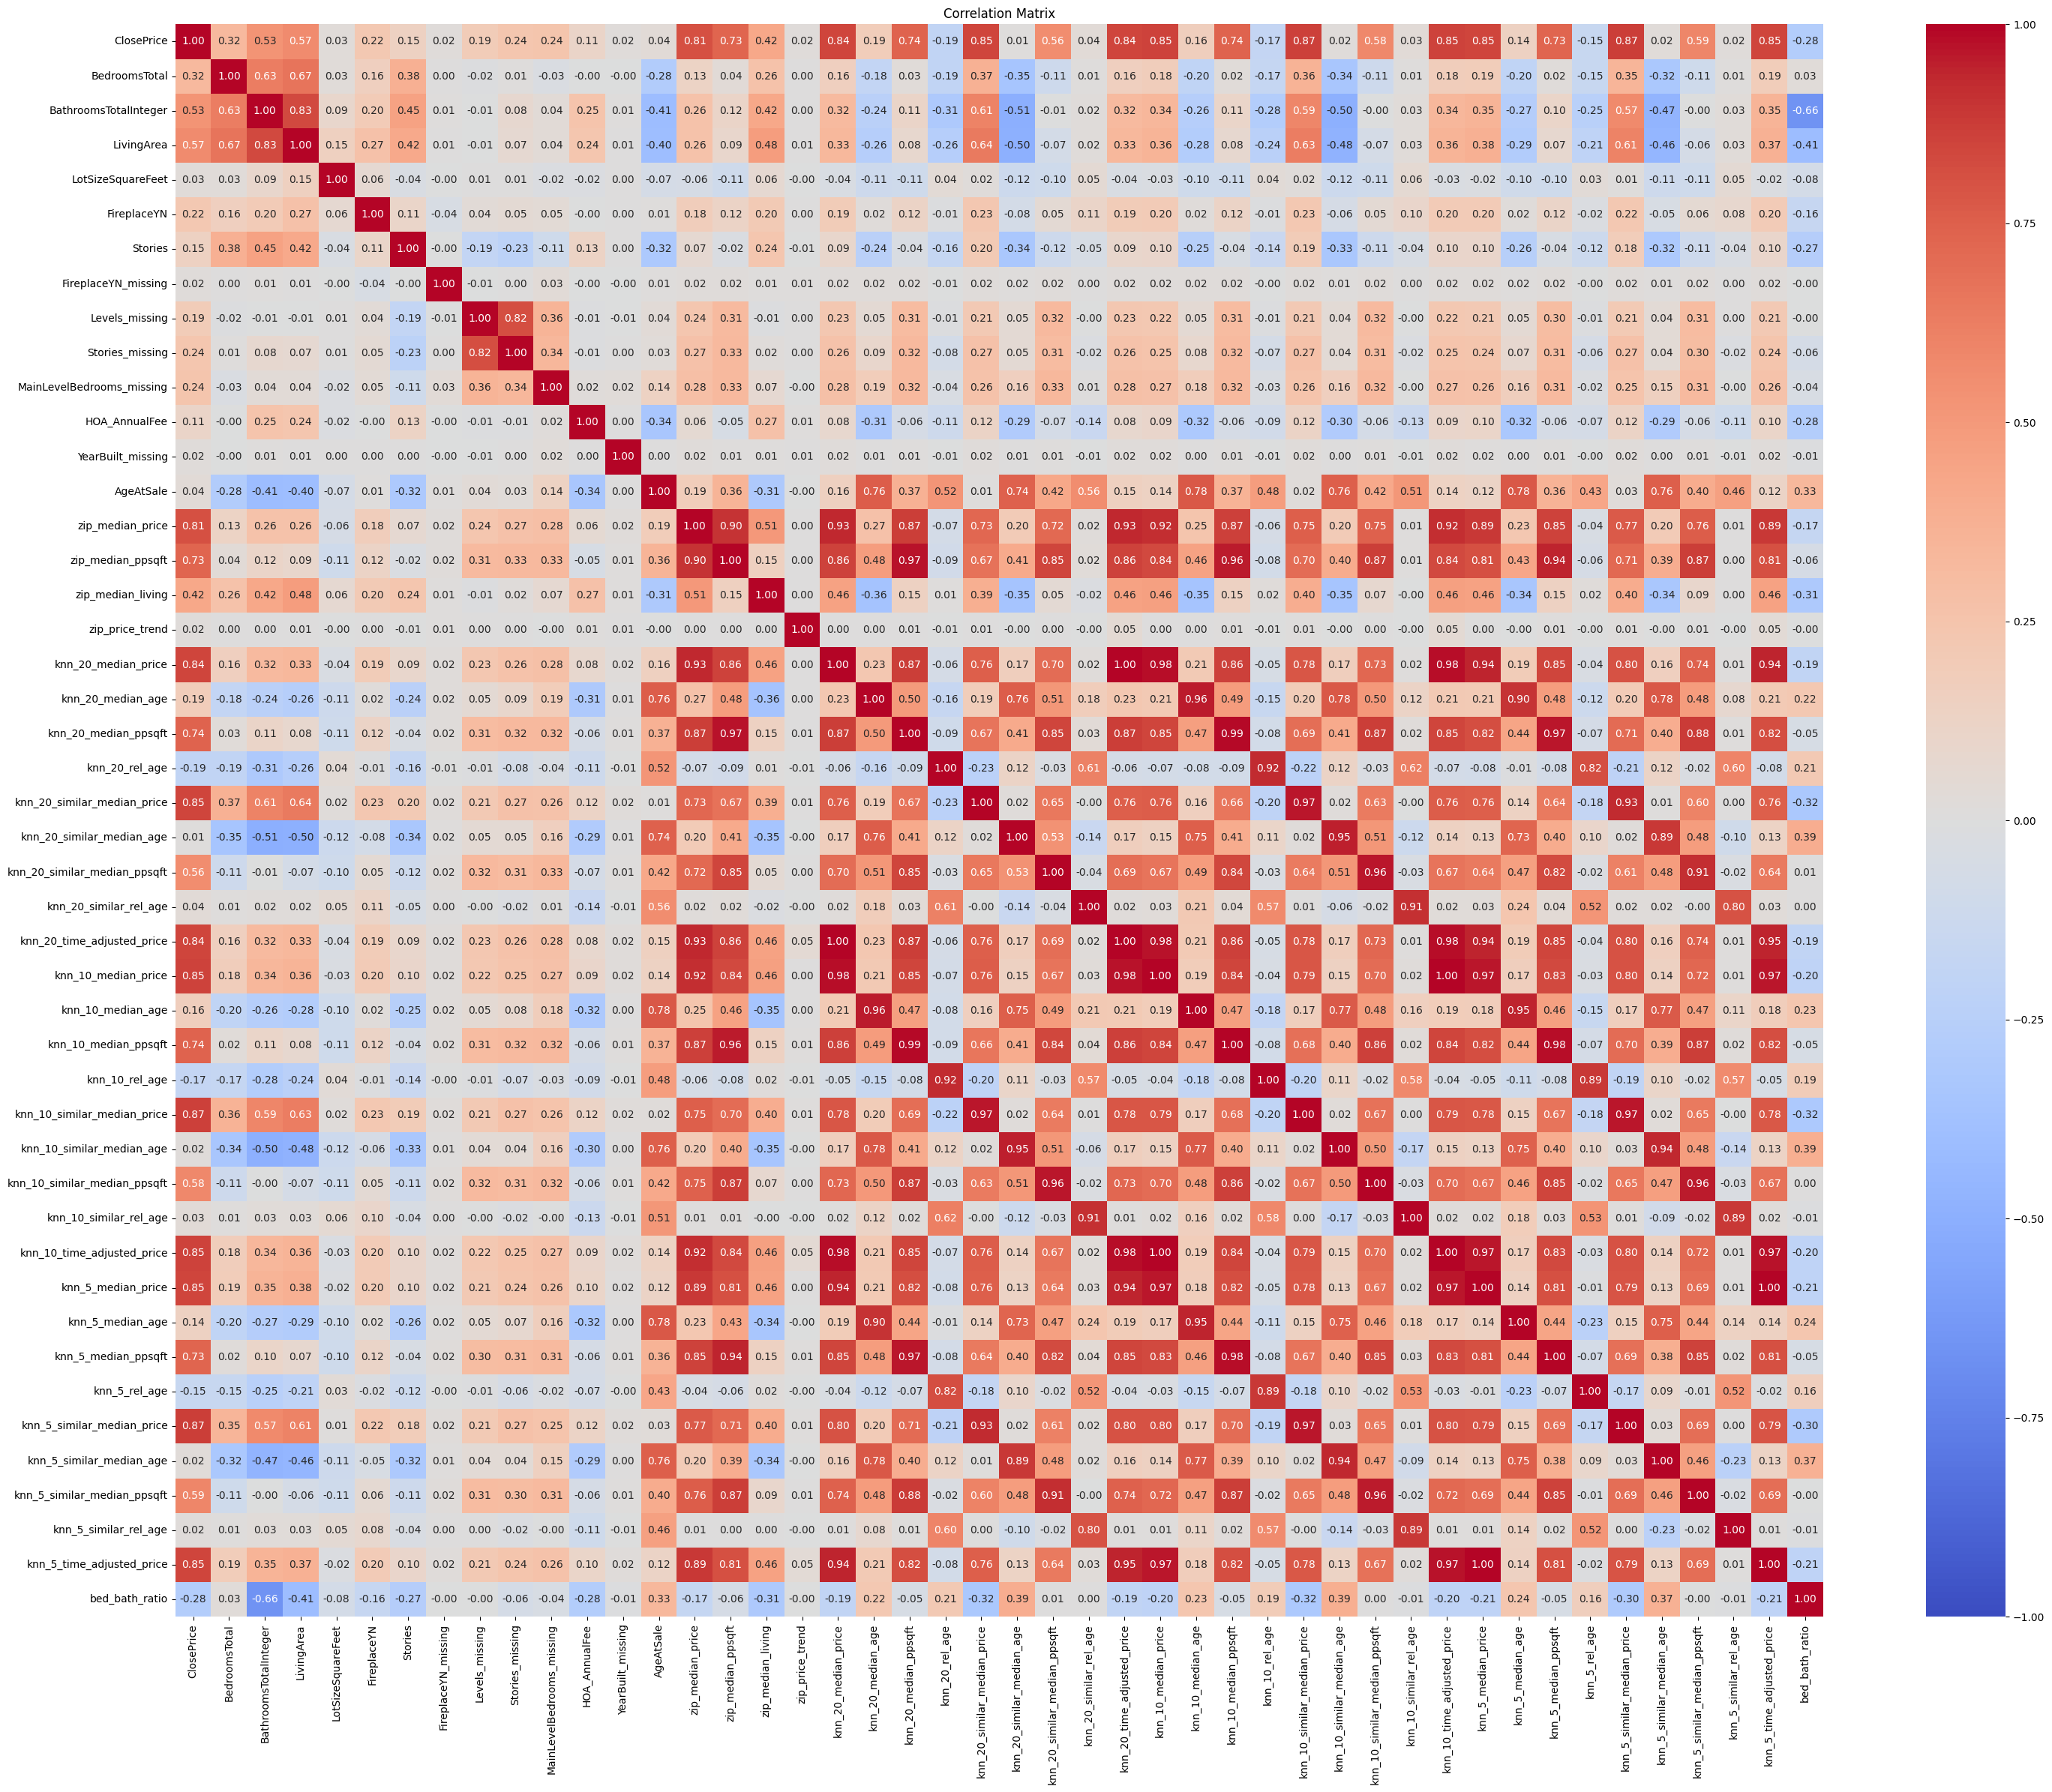

In [56]:
# Select numeric columns only
numeric_cols = train_full.select_dtypes(include=[np.number]).columns

corr = train_full[numeric_cols].corr()

plt.figure(figsize=(30, 24))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

/tmp/ipykernel_118121/915541092.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_corr.values, y=target_corr.index, palette="coolwarm")


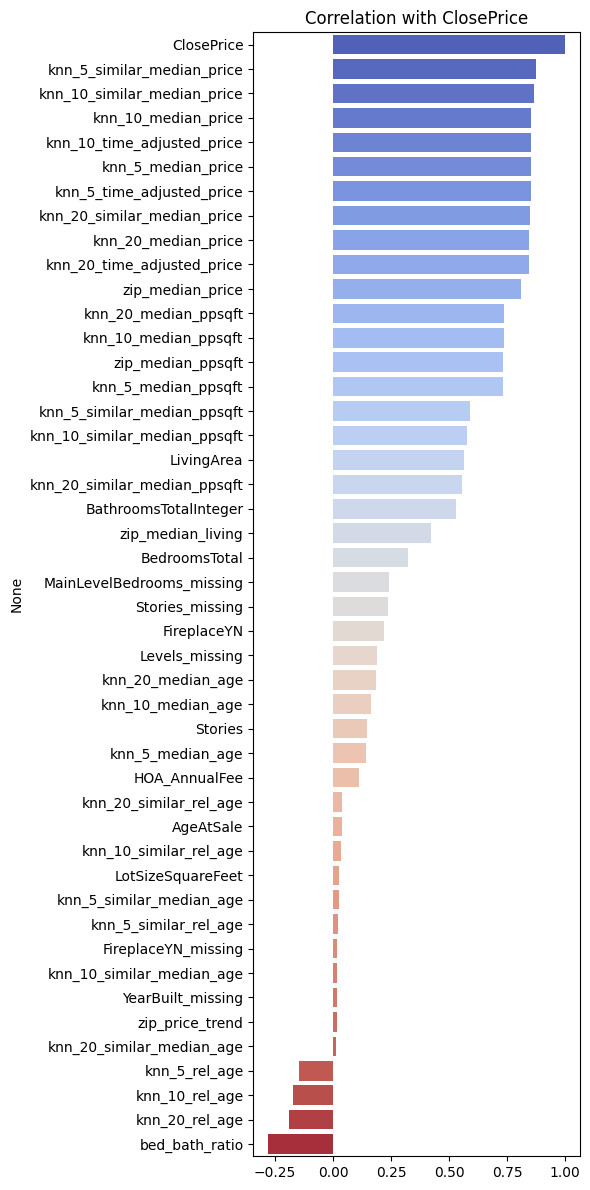

In [57]:
target_corr = corr["ClosePrice"].sort_values(ascending=False)

plt.figure(figsize=(6, 12))
sns.barplot(x=target_corr.values, y=target_corr.index, palette="coolwarm")
plt.title("Correlation with ClosePrice")
plt.tight_layout()
plt.show()

In [58]:
pd.set_option("display.max_info_columns", 9999)
pd.set_option("display.max_info_rows", 999999)
pd.set_option("display.max_columns", 9999)
pd.set_option("display.width", 2000)

In [59]:
train_full.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
Index: 121873 entries, 57983 to 179855
Data columns (total 46 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   ClosePrice                    121873 non-null  float64
 1   BedroomsTotal                 121873 non-null  float64
 2   BathroomsTotalInteger         121873 non-null  float64
 3   LivingArea                    121873 non-null  float64
 4   LotSizeSquareFeet             121873 non-null  float64
 5   FireplaceYN                   121873 non-null  int64  
 6   Stories                       121873 non-null  int64  
 7   FireplaceYN_missing           121873 non-null  int64  
 8   Levels_missing                121873 non-null  int64  
 9   Stories_missing               121873 non-null  int64  
 10  MainLevelBedrooms_missing     121873 non-null  int64  
 11  HOA_AnnualFee                 121873 non-null  float64
 12  YearBuilt_missing             121873 non-null

In [60]:
df_val.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10840 entries, 179856 to 190695
Data columns (total 46 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ClosePrice                    10840 non-null  float64
 1   BedroomsTotal                 10840 non-null  float64
 2   BathroomsTotalInteger         10840 non-null  float64
 3   LivingArea                    10840 non-null  float64
 4   LotSizeSquareFeet             10840 non-null  float64
 5   FireplaceYN                   10840 non-null  int64  
 6   Stories                       10840 non-null  int64  
 7   FireplaceYN_missing           10840 non-null  int64  
 8   Levels_missing                10840 non-null  int64  
 9   Stories_missing               10840 non-null  int64  
 10  MainLevelBedrooms_missing     10840 non-null  int64  
 11  HOA_AnnualFee                 10840 non-null  float64
 12  YearBuilt_missing             10840 non-null  int64  
 13  

In [61]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11678 entries, 190696 to 202373
Data columns (total 46 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ClosePrice                    11678 non-null  float64
 1   BedroomsTotal                 11678 non-null  float64
 2   BathroomsTotalInteger         11678 non-null  float64
 3   LivingArea                    11678 non-null  float64
 4   LotSizeSquareFeet             11678 non-null  float64
 5   FireplaceYN                   11678 non-null  int64  
 6   Stories                       11678 non-null  int64  
 7   FireplaceYN_missing           11678 non-null  int64  
 8   Levels_missing                11678 non-null  int64  
 9   Stories_missing               11678 non-null  int64  
 10  MainLevelBedrooms_missing     11678 non-null  int64  
 11  HOA_AnnualFee                 11678 non-null  float64
 12  YearBuilt_missing             11678 non-null  int64  
 13  

In [62]:
train_full.to_csv("train_wk6.csv", index=False)
df_val.to_csv("val_wk6.csv", index=False)
df_test.to_csv("test_wk6.csv", index=False)

files.download("train_wk6.csv")
files.download("val_wk6.csv")
files.download("test_wk6.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:
with open("cleaning_log_wk6.txt", "w") as f:
    for entry in cleaning_log:
        f.write(f"{entry}\n")


In [64]:
files.download("cleaning_log_wk6.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>